# 1.3 Continuous beams: moment distribution (Hardy Cross)

Moment distribution solves the joint-rotation equations by successive correction: lock every joint, release one at a time, share the out-of-balance moment
in proportion to stiffness, and carry half to the far end.

*Reference:* NPTEL, *Structural Analysis II*, Lesson 18. **Counter-clockwise member-end moments are positive.**

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

## Quantities used

| Quantity | Value |
|:--|:--|
| Member stiffness, far end fixed | $K = 4EI/l$ |
| Member stiffness, far end hinged | $K = 3EI/l$ (no carry-over to the hinge) |
| Distribution factor | $DF_i = K_i / \sum K$ |
| Carry-over factor | 1/2 |
| Fixed-end moments, UDL | $wl^2/12$ each end |
| Fixed-end moments, point load | $Pab^2/l^2$ at the left, $Pa^2b/l^2$ at the right |

Steps: (1) fixed-end moments; (2) release hinged ends once and carry over; (3) balance interior joints; (4) carry over; (5) repeat to convergence; (6) add the columns.

## Example 1: NPTEL Examples 18.1 and 18.2 (benchmark)

## Two-span beam, NPTEL Example 18.2

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Moment distribution

### Fixed-end moments, stiffness, distribution factors

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $w$ | $w = 2$ kN/m |
|  | $l_{1}$ | $l_{1} = 3$ m |
|  | $P$ | $P = 10$ kN |
|  | $l_{2}$ | $l_{2} = 4$ m |
|  | $a$ | $a = 2$ m |
|  | $b$ | $b = 2$ m |
| NPTEL L18 | Fixed-end moment<br>$F_{AB} = \dfrac{w\,l_{1}^{2}}{12}$<br>$\quad = \dfrac{2\times 3^{2}}{12}$ | $\mathbf{F_{AB} = 1.5}$ kN·m |
| NPTEL L18 | Fixed-end moment<br>$F_{BC} = \dfrac{P\,a\,b^{2}}{l_{2}^{2}}$<br>$\quad = \dfrac{10\times 2\times 2^{2}}{4^{2}}$ | $\mathbf{F_{BC} = 5}$ kN·m |
| NPTEL L18 | Far end fixed<br>$K_{BA} = \dfrac{4}{l_{1}}$<br>$\quad = \dfrac{4}{3}$ | $\mathbf{K_{BA} = 1.333}$ EI |
| NPTEL L18 | Far end hinged<br>$K_{BC} = \dfrac{3}{l_{2}}$<br>$\quad = \dfrac{3}{4}$ | $\mathbf{K_{BC} = 0.75}$ EI |
|  | $D_{BA} = \dfrac{K_{BA}}{K_{BA} + K_{BC}}$<br>$\quad = \dfrac{1.333}{1.333 + 0.75}$ | $\mathbf{D_{BA} = 0.64}$ |
|  | $D_{BC} = \dfrac{K_{BC}}{K_{BA} + K_{BC}}$<br>$\quad = \dfrac{0.75}{1.333 + 0.75}$ | $\mathbf{D_{BC} = 0.36}$ |
|  | Final moment at B (hogging): $M_{B}$ | $M_{B} = 5.34$ kN·m |
| NPTEL Ex. 18.2 | **Check:** matches the published 5.34 kN·m | ✅ **PASS** |


**Moment distribution (kN·m, counter-clockwise positive)**

| Step | AB | BA | BC | CB |
|:--|:-:|:-:|:-:|:-:|
| Distribution factor | – | 0.640 | 0.360 | – |
| FEM | 1.50 | -1.50 | 5.00 | -5.00 |
| Release hinged end |  |  |  | 5.00 |
| Carry-over |  |  | 2.50 |  |
| Balance |  | -3.84 | -2.16 |  |
| Carry-over | -1.92 |  |  |  |
| **Final** | **-0.42** | **-5.34** | **5.34** | **0.00** |


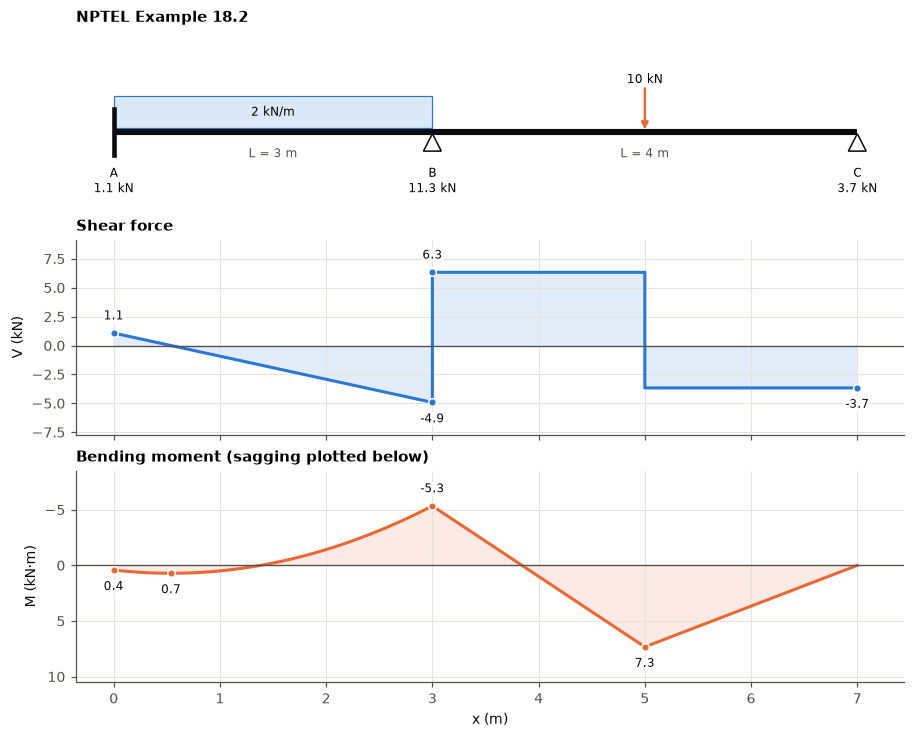

In [2]:
cb = ContinuousBeam([Span(3, [UDL(2)]), Span(4, [Point(10, 2)])], left="fixed")
M = cb.moment_distribution(); cb.diagrams()
s = Sheet("Two-span beam, NPTEL Example 18.2", element="Moment distribution")
s.let("w", 2, "kN/m"); s.let("l_1", 3, "m"); s.let("P", 10, "kN"); s.let("l_2", 4, "m"); s.let("a", 2, "m"); s.let("b", 2, "m")
s.calc("F_AB", "w*l_1**2/12", "kN·m", "NPTEL L18", "Fixed-end moment")
s.calc("F_BC", "P*a*b**2/l_2**2", "kN·m", "NPTEL L18", "Fixed-end moment")
s.calc("K_BA", "4/l_1", "EI", "NPTEL L18", "Far end fixed")
s.calc("K_BC", "3/l_2", "EI", "NPTEL L18", "Far end hinged")
s.calc("D_BA", "K_BA/(K_BA + K_BC)"); s.calc("D_BC", "K_BC/(K_BA + K_BC)")
s.let("M_B", abs(float(M[1])), "kN·m", "Final moment at B (hogging)")
s.verdict(abs(abs(M[1]) - 5.34) < 0.005, "matches the published 5.34 kN·m", "NPTEL Ex. 18.2")
s.show("Fixed-end moments, stiffness, distribution factors")
mdm_table(cb)
P.continuous(cb, "NPTEL Example 18.2")

## Example 2: NPTEL Example 18.3 (fixed end, different I, overhang of 15 kN·m)

**Moment distribution (kN·m, counter-clockwise positive)**

| Step | AB | BA | BC | CB |
|:--|:-:|:-:|:-:|:-:|
| Distribution factor | – | 0.333 | 0.667 | – |
| FEM | 16.00 | -16.00 | 7.50 | -7.50 |
| Release hinged end |  |  |  | -7.50 |
| Carry-over |  |  | -3.75 |  |
| Balance |  | 4.08 | 8.17 |  |
| Carry-over | 2.04 |  |  |  |
| **Final** | **18.04** | **-11.92** | **11.92** | **-15.00** |


**Hogging support moments**

| Support | NPTEL (kN·m) | This program (kN·m) |
|:--|:-:|:-:|
| A | 18.04 | 18.04 |
| B | 11.92 | 11.92 |
| C | 15 | 15 |


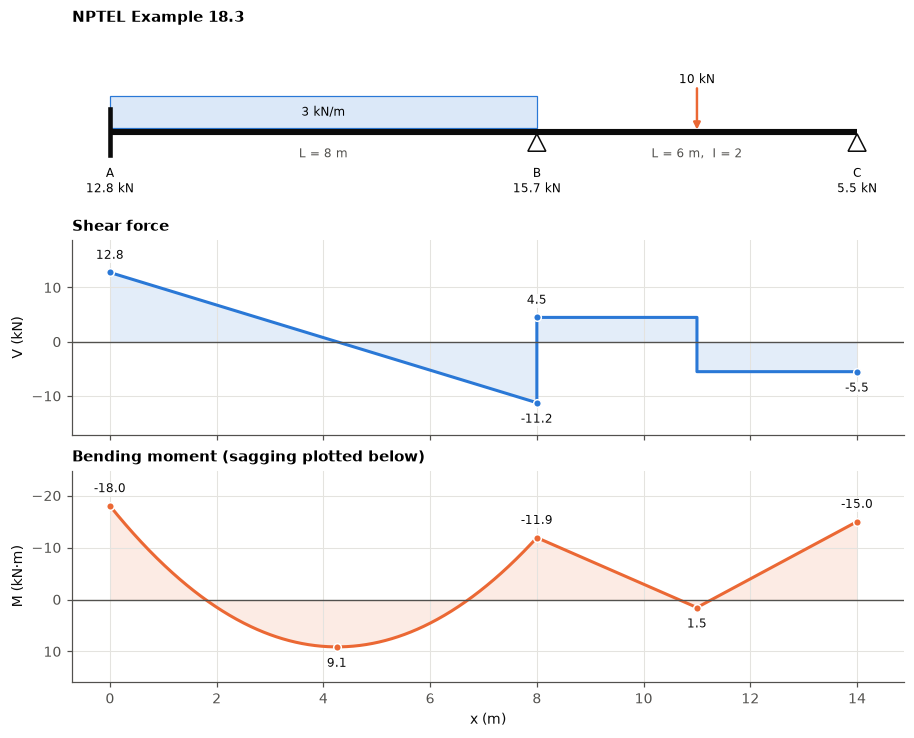

In [3]:
cb = ContinuousBeam([Span(8, [UDL(3)]), Span(6, [Point(10, 3)], I=2)], left="fixed", right=-15)
M = cb.moment_distribution(); cb.diagrams()
mdm_table(cb)
table([["A", 18.04, round(-M[0], 2)], ["B", 11.92, round(-M[1], 2)], ["C", 15.0, round(-M[2], 2)]], ["Support", "NPTEL (kN·m)", "This program (kN·m)"], "Hogging support moments")
P.continuous(cb, "NPTEL Example 18.3")

## Example 3: three spans, both methods compared

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `ex3_spans` | Spans from left to right | m, kN | list of `Span(...)` |

`UVL` and `Moment` are not accepted here.

**Writing spans and loads**

| Write | Meaning | Units |
|:--|:--|:--|
| `Point(P, a)` | Downward load P at a from the left end of its span | kN, m |
| `UDL(w)` or `UDL(w, a, b)` | Uniform load, over the whole span or from a to b | kN/m, m |
| `Span(L, [loads], I)` | One span; `I` is relative and optional | m |

Capital letters matter, and all loads of a span go inside one list: `Span(5.0, [UDL(20), Point(20, 3.4)])`.

**Not checked:** a load beyond its span, or a larger than b, runs without an error and gives wrong answers. A negative load means upward.

In [4]:
# INPUTS: edit only this cell, then run the cells below it
ex3_spans = [Span(5.0, [UDL(20)]), Span(6.0, [UDL(20), Point(40, 3.0)]), Span(4.0, [UDL(20)])]      # same as 1.2 Example 2

**Moment distribution (kN·m, counter-clockwise positive)**

| Step | AB | BA | BC | CB | CD | DC |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|
| Distribution factor | – | 0.474 | 0.526 | 0.471 | 0.529 | – |
| FEM | 41.67 | -41.67 | 90.00 | -90.00 | 26.67 | -26.67 |
| Release hinged end | -41.67 |  |  |  |  | 26.67 |
| Carry-over |  | -20.83 |  |  | 13.33 |  |
| Balance |  | -13.03 | -14.47 | 23.53 | 26.47 |  |
| Carry-over |  |  | 11.76 | -7.24 |  |  |
| Balance |  | -5.57 | -6.19 | 3.41 | 3.83 |  |
| Carry-over |  |  | 1.70 | -3.10 |  |  |
| Balance |  | -0.81 | -0.90 | 1.46 | 1.64 |  |
| Carry-over |  |  | 0.73 | -0.45 |  |  |
| Balance |  | -0.35 | -0.38 | 0.21 | 0.24 |  |
| … (further cycles) | … | … | … | … | … | … |
| **Final** | **0.00** | **-82.33** | **82.33** | **-72.30** | **72.30** | **0.00** |


## Comparison of methods

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Moment distribution vs three-moment

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Support A: three-moment 0.000 kN·m; moment distribution -0.000 kN·m |  |
|  | Support B: three-moment -82.327 kN·m; moment distribution -82.327 kN·m |  |
|  | Support C: three-moment -72.302 kN·m; moment distribution -72.302 kN·m |  |
|  | Support D: three-moment 0.000 kN·m; moment distribution 0.000 kN·m |  |
|  | **Check:** both methods agree | ✅ **PASS** |


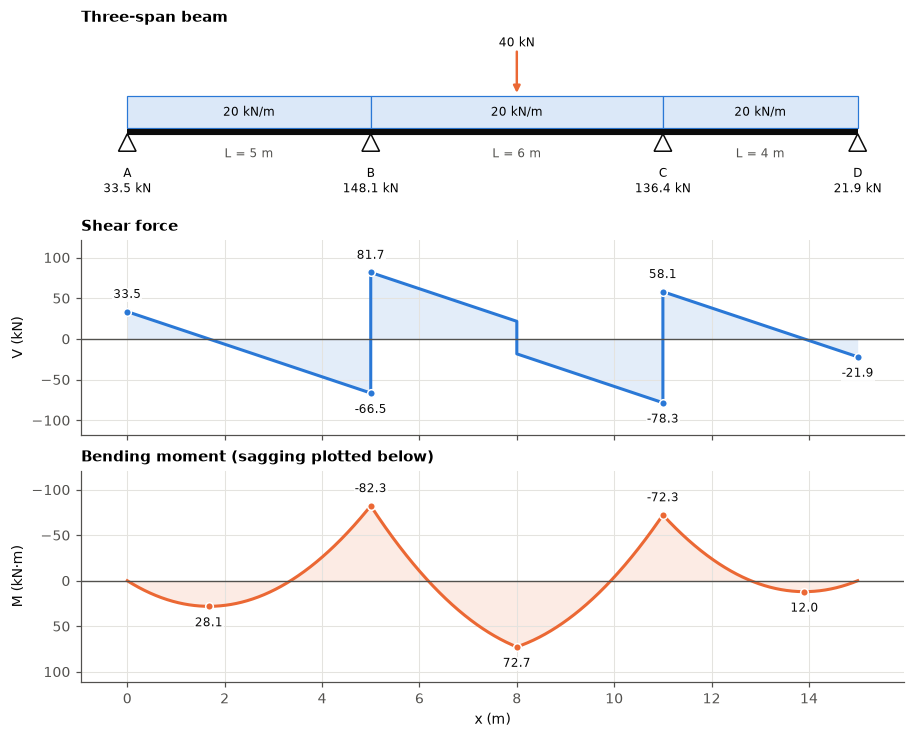

In [5]:
cb = ContinuousBeam(ex3_spans)
clap = cb.three_moment().copy(); hc = cb.moment_distribution(); cb.diagrams()
mdm_table(cb)
s = Sheet("Comparison of methods", element="Moment distribution vs three-moment")
for n, a, b in zip(cb.names, clap, hc):
    s.note(f"Support {n}: three-moment {a:.3f} kN·m; moment distribution {b:.3f} kN·m")
s.verdict(max(abs(clap - hc)) < 0.01, "both methods agree")
s.show()
P.continuous(cb, "Three-span beam")

## Example 4: fixed-ended beam (no joints to release)

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `ex4_spans` | Spans from left to right, both outer ends fixed | m, kN | list of `Span(...)` |

Loads are written as in Example 3.

In [6]:
# INPUTS: edit only this cell, then run the cells below it
ex4_spans = [Span(6, [UDL(15), Point(20, 2)])]

**Moment distribution (kN·m, counter-clockwise positive)**

| Step | AB | BA |
|:--|:-:|:-:|
| Distribution factor | – | – |
| FEM | 62.78 | -53.89 |
| **Final** | **62.78** | **-53.89** |


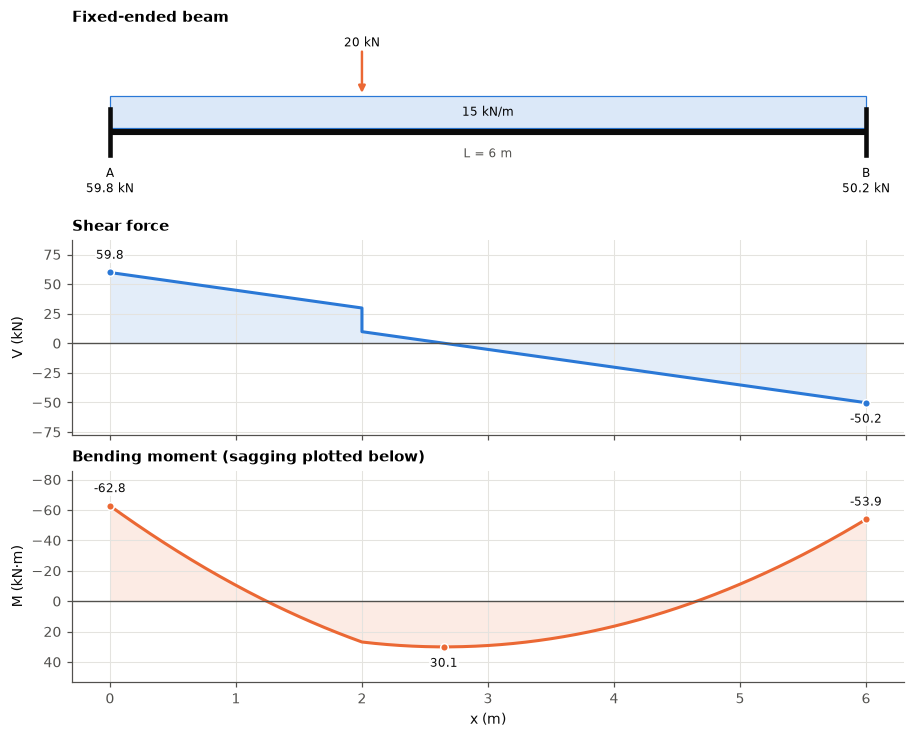

In [7]:
cb = ContinuousBeam(ex4_spans, left="fixed", right="fixed")
cb.moment_distribution(); cb.diagrams(); mdm_table(cb); P.continuous(cb, "Fixed-ended beam")

## Example 5: one joint of a braced frame (used for column moments in Section 5)

For a beam–column joint with remote ends fixed and the **beams at half stiffness**, the out-of-balance fixed-end moment is shared by stiffness.
Reference: BS 8110-1 3.2.1.2.5.

In [8]:
j = PJ.column_joint("B", 0)
s = Sheet("Edge column B1, joint with Beam B", element="One-joint distribution")
bw, hb = BRIEF["beam"]; cc = BRIEF["col"][0]; fl = PJ.flange("B", 0)
s.let("b_w", bw, "mm"); s.let("h_b", hb, "mm"); s.let("h_f", BRIEF["h_slab"], "mm"); s.let("L_b", fl["L"], "mm"); s.let("c", cc, "mm"); s.let("l_c", BRIEF["storey"] * 1000, "mm")
s.let("b_eff", fl["beff"], "mm", "Span value of the effective flange, used for the whole span", "EC2 5.3.2.1(3), (4); worked in Notebook 4.2")
s.calc("A_1", "(b_eff - b_w)*h_f", "mm²", "", "Flange outstands"); s.calc("A_2", "b_w*h_b", "mm²", "", "Web")
s.calc("y", "(A_1*h_f/2 + A_2*h_b/2)/(A_1 + A_2)", "mm", "", "Centroid from the top")
s.calc("I_b", "(b_eff - b_w)*h_f**3/12 + A_1*(y - h_f/2)**2 + b_w*h_b**3/12 + A_2*(h_b/2 - y)**2", "mm⁴", "EC2 5.4(2): uncracked section")
s.calc("k_b", "I_b/L_b/1000", "10³ mm³", "", "Beam I/L (E is common and cancels)")
s.calc("k_c", "c*c**3/12/l_c/1000", "10³ mm³", "", "Each column I/L")
s.let("FEM", j["f1"], "kN·m", "Fixed-end moment, span fully loaded (Notebook 4.1 loads)")
s.calc("M_col", "FEM*k_c/(2*k_c + 0.5*k_b)", "kN·m", "BS 8110-1 3.2.1.2.5", "Moment in each column")
s.verdict(abs(s["M_col"] - j["M"]) < 1e-6, "hand formula = program")
s.show()

## Edge column B1, joint with Beam B

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* One-joint distribution

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $b_{w}$ | $b_{w} = 300$ mm |
|  | $h_{b}$ | $h_{b} = 500$ mm |
|  | $h_{f}$ | $h_{f} = 175$ mm |
|  | $L_{b}$ | $L_{b} = 6000$ mm |
|  | $c$ | $c = 350$ mm |
|  | $l_{c}$ | $l_{c} = 3500$ mm |
| EC2 5.3.2.1(3), (4); worked in Notebook 4.2 | Span value of the effective flange, used for the whole span: $b_{eff}$ | $b_{eff} = 2260$ mm |
|  | Flange outstands<br>$A_{1} = \left(b_{eff} - b_{w}\right)\,h_{f}$<br>$\quad = \left(2260 - 300\right)\times 175$ | $\mathbf{A_{1} = 343000}$ mm² |
|  | Web<br>$A_{2} = b_{w}\,h_{b}$<br>$\quad = 300\times 500$ | $\mathbf{A_{2} = 150000}$ mm² |
|  | Centroid from the top<br>$y = \dfrac{\dfrac{A_{1}\,h_{f}}{2} + \dfrac{A_{2}\,h_{b}}{2}}{A_{1} + A_{2}}$<br>$\quad = \dfrac{\dfrac{343000\times 175}{2} + \dfrac{150000\times 500}{2}}{343000 + 150000}$ | $\mathbf{y = 136.9}$ mm |
| EC2 5.4(2): uncracked section | $I_{b} = \dfrac{\left(b_{eff} - b_{w}\right)\,h_{f}^{3}}{12} + A_{1}\,\left(y - \dfrac{h_{f}}{2}\right)^{2} + \dfrac{b_{w}\,h_{b}^{3}}{12} + A_{2}\,\left(\dfrac{h_{b}}{2} - y\right)^{2}$<br>$\quad = \dfrac{\left(2260 - 300\right)\times 175^{3}}{12} + 343000\times \left(136.9 - \dfrac{175}{2}\right)^{2} + \dfrac{300\times 500^{3}}{12} + 150000\times \left(\dfrac{500}{2} - 136.9\right)^{2}$ | $\mathbf{I_{b} = 6.756\times10^{9}}$ mm⁴ |
|  | Beam I/L (E is common and cancels)<br>$k_{b} = \dfrac{\dfrac{I_{b}}{L_{b}}}{1000}$<br>$\quad = \dfrac{\dfrac{6.756\times10^{9}}{6000}}{1000}$ | $\mathbf{k_{b} = 1126}$ 10³ mm³ |
|  | Each column I/L<br>$k_{c} = \dfrac{\dfrac{\dfrac{c\,c^{3}}{12}}{l_{c}}}{1000}$<br>$\quad = \dfrac{\dfrac{\dfrac{350\times 350^{3}}{12}}{3500}}{1000}$ | $\mathbf{k_{c} = 357.3}$ 10³ mm³ |
|  | Fixed-end moment, span fully loaded (Notebook 4.1 loads): $\mathrm{FEM}$ | $\mathrm{FEM} = 176.2$ kN·m |
| BS 8110-1 3.2.1.2.5 | Moment in each column<br>$M_{col} = \dfrac{\mathrm{FEM}\,k_{c}}{2\,k_{c} + 0.5\,k_{b}}$<br>$\quad = \dfrac{176.2\times 357.3}{2\times 357.3 + 0.5\times 1126}$ | $\mathbf{M_{col} = 49.28}$ kN·m |
|  | **Check:** hand formula = program | ✅ **PASS** |
